## Time Series Classification Using CNN / RNN / Attention 

#### Exercise 1: on a toy dataset

The function given below generates (2*n_series_per_class) time series of length (length+length_padding) and assign a binary label (y) to each time series

### > 1. The Toy Dataset: Sine Waves

The dataset is generated as follows:

- **Class 0**: $X_0(t) = \sin(t) + \epsilon$  
- **Class 1**: $X_1(t) = \sin(-t) + \epsilon$  

where $\epsilon$ is Gaussian noise: $0.02 \times \text{random normal distribution}$.  

- **Padding**: `length_padding` appends uninformative signals to the end of sequences.  
  This tests whether the network can remember the early, class-distinguishing part of the sequence through a long period of noise.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def make_sines(n_series_per_class, length, length_padding=0):
    """
    Generates a synthetic dataset of sine waves for binary classification.
    
    Parameters:
    - n_series_per_class: Number of samples to generate for each class.
    - length: The number of time steps for the informative part of the signal.
    - length_padding: Extra uninformative time steps added to the end.
    """
    # Create the time axis for the informative signal (one full cycle)
    t = np.linspace(0, 2 * np.pi, num=length)
    
    # --- CLASS 0 GENERATION ---
    # Initialize with small Gaussian noise
    X0 = .02 * np.random.randn(n_series_per_class, length + length_padding)
    # Add a standard sine wave sin(t) to the first 'length' steps
    X0[:, :length] += np.sin(t).reshape((1, -1))
    # Add a common sine wave to the padding (not useful for classification)
    X0[:, length:] += np.sin(np.linspace(0, 2 * np.pi, num=length_padding))
    
    # --- CLASS 1 GENERATION ---
    # Initialize with small Gaussian noise
    X1 = .02 * np.random.randn(n_series_per_class, length + length_padding)
    # Add an inverted/phase-shifted sine wave sin(-t) to the first 'length' steps
    X1[:, :length] += np.sin(-t).reshape((1, -1))
    # Add the same common sine wave to the padding
    X1[:, length:] += np.sin(np.linspace(0, 2 * np.pi, num=length_padding))

    # Combine classes and reshape to (Samples, TimeSteps, Features) for Deep Learning models
    dataset = np.array([X0, X1]).reshape((2 * n_series_per_class, length + length_padding, 1))
    
    # Create labels: 0 for the first class, 1 for the second
    y = np.array([0] * n_series_per_class + [1] * n_series_per_class)

    # Shuffle the dataset so the model doesn't see all Class 0 then all Class 1
    indices = np.random.permutation(2 * n_series_per_class)
    
    return dataset[indices], y[indices]

"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This script creates a controlled environment to evaluate if a Neural Network 
can distinguish between sin(t) and sin(-t). This is a test of "Phase Sensitivity" 
or "Directionality" in time series.

2. THE MATHS:
- Signal Equation: X(t) = A * sin(ωt + φ) + ε
- Where A is amplitude, φ is phase, and ε is Gaussian noise.
- Class 0 (φ=0) vs Class 1 (φ=π or t is negative).



3. KEY POINTS & CODE NOTIONS:
- CHANNEL DIMENSION: The use of 'np.newaxis' or '.reshape(..., 1)' is mandatory 
  for 1D Convolutional (CNN) or Recurrent (RNN) layers.
- PADDING STRATEGY: By adding identical sine-padding to both classes, we force 
  the model to learn "where" the informative part of the signal is located, 
  similar to the attention mechanism's goal.



4. TRICKY PLACES:
- SHUFFLING: If you forget 'np.random.permutation', the model might reach a 
  local minimum by predicting only one class for the first half of the epoch.
- SINE VS INVERTED: In a standard MLP (Dense network), these two signals 
  might look similar if they are just treated as a 'bag of values.' 
  CNNs and RNNs are required to respect the order of the points.
- NOISE LEVEL: If the noise ε (.02) is too high, the local 'direction' 
  becomes indistinguishable, and the model accuracy will drop to 50%.
"""

'\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThis script creates a controlled environment to evaluate if a Neural Network \ncan distinguish between sin(t) and sin(-t). This is a test of "Phase Sensitivity" \nor "Directionality" in time series.\n\n2. THE MATHS:\n- Signal Equation: X(t) = A * sin(ωt + φ) + ε\n- Where A is amplitude, φ is phase, and ε is Gaussian noise.\n- Class 0 (φ=0) vs Class 1 (φ=π or t is negative).\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- CHANNEL DIMENSION: The use of \'np.newaxis\' or \'.reshape(..., 1)\' is mandatory \n  for 1D Convolutional (CNN) or Recurrent (RNN) layers.\n- PADDING STRATEGY: By adding identical sine-padding to both classes, we force \n  the model to learn "where" the informative part of the signal is located, \n  similar to the attention mechanism\'s goal.\n\n\n\n4. TRICKY PLA

The function returns the data in a 3D shape: (Batch_Size, Time_Steps, Features).
* Batch_Size: Total number of series (2×n_series_per_class).
* Time_Steps: Total length (length+length_padding).
* Features: 1 (since it is a univariate time series).

This format is the standard input requirement for layers like LSTM, SimpleRNN, and Conv1D in frameworks like TensorFlow/Keras and PyTorch.

When you perform X0[:, :length] += np.sin(t).reshape((1, -1)), NumPy uses Broadcasting. It takes that single row of sine wave data and "stretches" (repeats) it vertically across every single row in X0.

---

Questions: 
 - Generate a dataset with n_series_per_class = 25, length = 100, length_padding = 10
 - Plot the time series on a same graph with different colors for the class y
 - What seems to differenciate both classes ?
 - Try with a longer value of length_padding to understand its impact

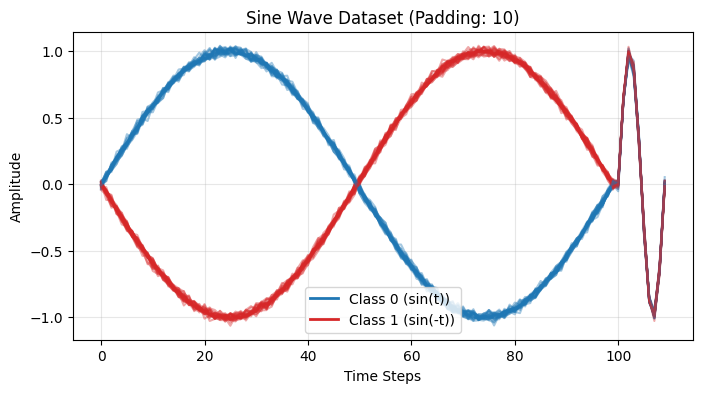

"\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThis plot visualizes the dataset's discriminative features: the blue lines \nrepresent the standard sine wave (Class 0), while red lines represent the \nphase-shifted/time-reversed sine wave (Class 1).\n\n2. THE MATHS:\n- Class Separation: The models must learn to distinguish between f(t) = sin(t) \n  and f(t) = sin(-t).\n- Discriminative Region: The informative signal exists between t=[0, 100]. \n- Non-discriminative Region (Padding): From t=[100, 110], both classes \n  follow the same sin(t) path, providing no useful classification info.\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- OVERLAP: Note how both classes cross zero at the same points. A simple \n  average of the values would be identical (zero), meaning the model MUST \n  use temporal order to succeed.\n- ALPHA BLENDI

In [2]:
# 1. GENERATE THE DATASET
# Using our function to create 50 total series (25 per class)
n_per_class = 25
len_sig = 100
pad = 10

X_toy, y_toy = make_sines(n_series_per_class=n_per_class, length=len_sig, length_padding=pad)

# 2. PLOTTING THE TIME SERIES
plt.figure(figsize=(8, 4))
for i in range(len(X_toy)):
    # Class 0 (sin(t)) in Blue, Class 1 (sin(-t)) in Red
    color = 'tab:blue' if y_toy[i] == 0 else 'tab:red'
    # .plot expects 2D data, but our X_toy is 3D (Samples, Steps, 1), 
    # so matplotlib automatically squeezes the last dimension.
    plt.plot(X_toy[i], color=color, alpha=0.4)

plt.title(f"Sine Wave Dataset (Padding: {pad})")
plt.xlabel("Time Steps")
plt.ylabel("Amplitude")

# 3. LEGEND CONSTRUCTION
# Since we plotted in a loop, we create manual proxies for the legend
from matplotlib.lines import Line2D
custom_lines = [Line2D([0], [0], color='tab:blue', lw=2),
                Line2D([0], [0], color='tab:red', lw=2)]
plt.legend(custom_lines, ['Class 0 (sin(t))', 'Class 1 (sin(-t))'])
plt.grid(True, alpha=0.3)
plt.show()

"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This plot visualizes the dataset's discriminative features: the blue lines 
represent the standard sine wave (Class 0), while red lines represent the 
phase-shifted/time-reversed sine wave (Class 1).

2. THE MATHS:
- Class Separation: The models must learn to distinguish between f(t) = sin(t) 
  and f(t) = sin(-t).
- Discriminative Region: The informative signal exists between t=[0, 100]. 
- Non-discriminative Region (Padding): From t=[100, 110], both classes 
  follow the same sin(t) path, providing no useful classification info.



3. KEY POINTS & CODE NOTIONS:
- OVERLAP: Note how both classes cross zero at the same points. A simple 
  average of the values would be identical (zero), meaning the model MUST 
  use temporal order to succeed.
- ALPHA BLENDING: Setting alpha=0.4 allows us to see the 'density' of the 
  noise ε around the main sine signals.

4. TRICKY PLACES:
- THE PADDING TRAP: A model with a large 'Global Average' might get 
  confused by the padding. The goal is to see if the network learns to 
  focus on the first 100 steps and ignore the last 10.
- VISUAL INSPECTION: If the red and blue lines are completely on top of 
  each other, the classification task is impossible. This plot confirms 
  that they are indeed different enough to be classified.
"""

*Observations* :The fundamental difference between the two classes is the Phase Shift (or Polarity) of the initial sine waves
* Class 0 (Blue): Follows the function f(t)=sin(t). It starts by moving in a positive direction (upward) from zero.
* Class 1 (Red): Follows the function f(t)=sin(−t), which is mathematically equivalent to −sin(t). It starts by moving in a negative direction (downward) from zero.
* After step 100, both classes transition into the "padding" zone where they share the exact same signal, making them indistinguishable in that latter portion.

We will start by using parameters n_series_per_class = 100, length = 50, length_padding = 5.
Question: Generate two datasets (one for training and one for testing) with these parameters

In [ ]:
# --- 1. DATA PARAMETERIZATION ---
# Number of samples per class (Total N = 200)
n_series_per_class = 100
# Informative part of the sine wave (50 time steps)
length = 50
# Non-informative padding (5 time steps) added to the end
length_padding = 5

# --- 2. DATASET GENERATION ---
# We create two independent sets to ensure the model generalizes to new data
X_train, y_train = make_sines(n_series_per_class, length, length_padding)
X_test, y_test = make_sines(n_series_per_class, length, length_padding)

# --- 3. DIMENSIONALITY VERIFICATION ---
# Expected shape: (Samples, TimeSteps, Channels) -> (200, 55, 1)
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This code prepares the inputs for the embedding function f that maps temporal 
sequences into a non-temporal vector space. 
The shape (200, 55, 1) signifies 200 distinct observations, each with a duration 
of 55 timestamps across a single feature/channel.

2. THE MATHS:
- Embedding Function: f(X) = [e₁, ..., eₖ] where k is the number of features 
  learned by the neural network.
- Data Splitting: Using separate train/test sets is vital to evaluate 
  generalization—the model's ability to classify signals it has never 
  'seen' before.



3. KEY POINTS & CODE NOTIONS:
- CHANNEL DIMENSION: Deep learning frameworks require the trailing '1' 
  dimension even for univariate series. 
- PADDING RATIO: Here, padding is ~9% of the signal. This is a small distractor 
  intended to test if the model can focus on the phase of the first 50 steps 
 .

4. TRICKY PLACES:
- DATA LEAKAGE: If make_sines was called only once and the data was split 
  poorly, the model might memorize specific noise patterns.
- INPUT_SHAPE: In the next steps, the 'input_shape' of the layers must match 
  (55, 1), not (50, 1) or (200, 55, 1).
"""

X_train shape: (200, 55, 1)
y_train shape: (200,)
X_test shape: (200, 55, 1)
y_test shape: (200,)


"\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThis code prepares the inputs for the embedding function f that maps temporal \nsequences into a non-temporal vector space. \nThe shape (200, 55, 1) signifies 200 distinct observations, each with a duration \nof 55 timestamps across a single feature/channel.\n\n2. THE MATHS:\n- Embedding Function: f(X) = [e₁, ..., eₖ] where k is the number of features \n  learned by the neural network.\n- Data Splitting: Using separate train/test sets is vital to evaluate \n  generalization—the model's ability to classify signals it has never \n  'seen' before.\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- CHANNEL DIMENSION: Deep learning frameworks require the trailing '1' \n  dimension even for univariate series. \n- PADDING RATIO: Here, padding is ~9% of the signal. This is a small distractor

* Shape of (200,55,1) is standard for Deep Learning models processing sequences (RNNs, LSTMs, and 1D-CNNs)
* Shape : (samples, Timestep, Features)
* Features (1): The third dimension represents the number of variables measured at each time step. Since we only have the amplitude of a single sine wave, this is a univariate time series, hence the 1.


The code uses .reshape((..., 1)) specifically to add that third "Feature" dimension, even though there is only one feature, so that the data is compatible with the SimpleRNN or Conv1D layers used in the subsequent cells.

---

Questions: 
1) Build a simple neural network model composed of:
 - one Vanilla RNN layer (SimpleRNN Layer in Keras) with only a few units
 - one output classification layer

2)Train this model using the training set with the test set as the validation data
What is the validation accuracy that you obtain?

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# 1) Build the model using the Sequential API
# Sequential means we are stacking layers one after another in a linear fashion
model_rnn = Sequential([
    # The SimpleRNN layer:
    # units=8: This is the dimensionality of the output space (hidden state). 
    # It means the model has 8 'neurons' that try to remember patterns in the sequence.
    # input_shape=(55, 1): The model expects 55 time steps and 1 feature per step 
    # (even the input shape (200,55,1) model needs the shape of one sample).
    SimpleRNN(units=8, input_shape=(X_train.shape[1], 1)), 
    
    # The Output Layer:
    # units=1: We want a single value as output (the probability of being Class 1).
    # activation='sigmoid': Squashes the output between 0 and 1, perfect for binary classification.
    Dense(1, activation='sigmoid')
])

# 2) Compile the model
# optimizer='adam':
# loss='binary_crossentropy': The error in 0/1 classification.
model_rnn.compile(optimizer='adam', 
                  loss='binary_crossentropy', 
                  metrics=['accuracy'])

# Show the architecture summary (number of parameters to train)
# model_rnn.summary()


"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
The RNN is the most natural architecture for this toy problem because it 
processes the sine wave point-by-point, maintaining a state that "remembers" 
if the wave is currently moving upward or downward.

2. THE MATHS:
- Recurrent Step: h_t = tanh( W_h * h_{t-1} + W_x * x_t + b )
- Where h_t is the state at time t, x_t is the current sine value, and 
  W matrices are the learned weights.
- Information Flow: The model updates h_t 55 times. The final state (h_55) 
  is used to make the prediction.



3. KEY POINTS & CODE NOTIONS:
- SEQUENTIAL BOTTLENECK: Unlike CNNs which can look at windows in parallel, 
  RNNs must calculate h_1 before h_2, making them harder to parallelize on GPUs.
- MANY-TO-ONE: This is a 'many-to-one' architecture—it takes many time steps 
  as input and produces one single classification label as output.

4. TRICKY PLACES:
- VANISHING GRADIENTS: In a SimpleRNN, the influence of the very first sine 
  points can "fade" by the time the model reaches step 55. If the padding 
  was much longer, the model might forget the informative start of the signal.
- UNITS VS. PARAMETERS: With only 8 units, the model is very lightweight. 
  The total parameters are roughly (units * units) + (units * input_dim) + units, 
  making it less prone to overfitting than a large Dense network.
"""

2026-02-04 11:08:03.857338: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-04 11:08:03.920918: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-04 11:08:05.471427: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/export/tf2onnx_

'\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThe RNN is the most natural architecture for this toy problem because it \nprocesses the sine wave point-by-point, maintaining a state that "remembers" \nif the wave is currently moving upward or downward.\n\n2. THE MATHS:\n- Recurrent Step: h_t = tanh( W_h * h_{t-1} + W_x * x_t + b )\n- Where h_t is the state at time t, x_t is the current sine value, and \n  W matrices are the learned weights.\n- Information Flow: The model updates h_t 55 times. The final state (h_55) \n  is used to make the prediction.\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- SEQUENTIAL BOTTLENECK: Unlike CNNs which can look at windows in parallel, \n  RNNs must calculate h_1 before h_2, making them harder to parallelize on GPUs.\n- MANY-TO-ONE: This is a \'many-to-one\' architecture—it takes many time st

* By default, Keras's SimpleRNN only returns the hidden state of the very last time step (the 55th step). It discards all intermediate "memories" and passes only that final summary to the Dense layer. This is why the Dense layer is able to take the output and turn it into a single classification (0 or 1).

* Because units=8 is very small, this model is lightweight but prone to the vanishing gradient problem if the sequences get much longer.

In [6]:
# Training on GPU
import tensorflow as tf

# 1. Hardware Check: Identify if a Graphics Processing Unit (GPU) is available.
# GPUs are much faster than CPUs for the matrix multiplications required by Neural Nets.
gpus = tf.config.list_physical_devices('GPU')

# 2. Device Context: Force the following block of code to run on the first GPU.
with tf.device('/GPU:0'):
    # 3. The Fit Method: This is the actual "Learning" process.
    history = model_rnn.fit(
        X_train, y_train,        # Training data and their ground-truth labels
        epochs=20,               # Number of times the model sees the entire dataset
        batch_size=16,           # Number of samples processed before updating weights
        validation_data=(X_test, y_test), # Data used to check accuracy on "unseen" examples
        verbose=0               # Progress bar mode (0=silent, 1=progress bar)
    )

# 3. Print Final Scores
# Option A: Get the last values from the history dictionary
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]

# Option B: Re-evaluate on the test set for a formal final score
test_loss, test_acc = model_rnn.evaluate(X_test, y_test, verbose=0)

print("-" * 30)
print(f"Final Training Accuracy:   {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Final Test Loss:           {test_loss:.4f}")
print("-" * 30)


"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This phase is the "optimization" of the embedding function f. The model 
adjusts its internal RNN weights so that Class 0 signals result in a probability 
near 0, and Class 1 signals result in a probability near 1.

2. THE MATHS:
- Backpropagation Through Time (BPTT): Since it's an RNN, the error is 
  calculated at the last step (t=55) and propagated back through all 
  previous time steps to update the weights.
- Loss Function (Binary Crossentropy): 
    L = - [y * log(ŷ) + (1 - y) * log(1 - ŷ)]
  The GPU calculates the gradient (∂L/∂W) for 16 samples (the batch) at once 
  using parallel processing.



3. KEY POINTS & CODE NOTIONS:
- VALIDATION_DATA: This is the "Gold Standard" for performance. If Training 
  Accuracy is 100% but Validation Accuracy is 50%, the model has 
  memorized the noise (Overfitting).
- BATCH_SIZE: Smaller batches (like 16) introduce "noise" into the 
  gradient updates, which ironically helps the model avoid local minima.

4. TRICKY PLACES:
- GPU CONTEXT: In modern TensorFlow, 'with tf.device' is often unnecessary as 
  TF defaults to the GPU. However, explicitly defining it prevents the 
  code from accidentally running on the much slower CPU.
- CONVERGENCE: For this toy sine problem, the model should reach ~90-100% 
  accuracy within 20 epochs. If it stays at 50%, it usually means the 
  learning rate is too high or the 'input_shape' is mismatched.
"""

------------------------------
Final Training Accuracy:   1.0000
Final Validation Accuracy: 1.0000
Final Test Loss:           0.0358
------------------------------


'\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThis phase is the "optimization" of the embedding function f. The model \nadjusts its internal RNN weights so that Class 0 signals result in a probability \nnear 0, and Class 1 signals result in a probability near 1.\n\n2. THE MATHS:\n- Backpropagation Through Time (BPTT): Since it\'s an RNN, the error is \n  calculated at the last step (t=55) and propagated back through all \n  previous time steps to update the weights.\n- Loss Function (Binary Crossentropy): \n    L = - [y * log(ŷ) + (1 - y) * log(1 - ŷ)]\n  The GPU calculates the gradient (∂L/∂W) for 16 samples (the batch) at once \n  using parallel processing.\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- VALIDATION_DATA: This is the "Gold Standard" for performance. If Training \n  Accuracy is 100% but Validation Accuracy is

Questions: 
 - Same questions but with a dataset such that length = 50 and length_padding = 50
 - What do you observe?

In [12]:
# Parameters for long-term dependency test
n_series_per_class = 1000 #100
length = 50
length_padding =  50 #50 # Total length = 100

X_long, y_long = make_sines(n_series_per_class, length, length_padding)
X_test_long, y_test_long = make_sines(n_series_per_class, length, length_padding)


In [13]:
model_long = Sequential([
    SimpleRNN(units=8, input_shape=(X_long.shape[1], 1)), 
    Dense(1, activation='sigmoid')
])

model_long.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

with tf.device('/GPU:0'):
    history_long = model_long.fit(
        X_long, y_long, 
        epochs=30, 
        validation_data=(X_test_long, y_test_long),
        verbose=0
    )

# 3. Print Final Scores
# Option A: Get the last values from the history dictionary
final_train_acc = history_long.history['accuracy'][-1]
final_val_acc = history_long.history['val_accuracy'][-1]

# Option B: Re-evaluate on the test set for a formal final score
test_loss, test_acc = model_long.evaluate(X_test_long, y_test_long, verbose=0)

print("-" * 30)
print(f"Final Training Accuracy:   {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Final Test Loss:           {test_loss:.4f}")
print("-" * 30)

"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This experiment tests the "Vanishing Gradient" problem. In theory, an RNN can 
handle any length, but in practice, standard SimpleRNNs struggle to "remember" 
the start of a long sequence by the time they reach the end.

2. THE MATHS:
- Gradient Decay: During Backpropagation Through Time (BPTT), the gradient is 
  multiplied by the weight matrix W at every time step.
- Result: If the sequence is long (e.g., length > 100), the gradient effectively 
  becomes zero (vanishes) or infinite (explodes), meaning the weights at the 
  beginning of the sine wave are never updated correctly.



3. KEY POINTS & CODE NOTIONS:
- X_LONG SHAPE: The input shape here is likely much larger than the previous 
  55 steps. The model must compress more temporal information into the same 
  8 hidden units.
- VALIDATION GAP: If Training Accuracy is high but Validation is low, the 
  model may be struggling with the increased noise present in longer synthetic 
  data.

4. TRICKY PLACES:
- THE "FORGETTING" EFFECT: Because the informative part of the signal is at 
  the start and the padding is at the end, the SimpleRNN may "overwrite" its 
  memory with the uninformative padding by the time it makes a prediction.
- SOLUTION: This is why advanced layers like LSTM (Long Short-Term Memory) 
  or GRU were invented—to provide a "shortcut" for gradients to flow 
  across long time distances.
"""

------------------------------
Final Training Accuracy:   0.4890
Final Validation Accuracy: 0.4965
Final Test Loss:           0.6938
------------------------------


'\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThis experiment tests the "Vanishing Gradient" problem. In theory, an RNN can \nhandle any length, but in practice, standard SimpleRNNs struggle to "remember" \nthe start of a long sequence by the time they reach the end.\n\n2. THE MATHS:\n- Gradient Decay: During Backpropagation Through Time (BPTT), the gradient is \n  multiplied by the weight matrix W at every time step.\n- Result: If the sequence is long (e.g., length > 100), the gradient effectively \n  becomes zero (vanishes) or infinite (explodes), meaning the weights at the \n  beginning of the sine wave are never updated correctly.\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- X_LONG SHAPE: The input shape here is likely much larger than the previous \n  55 steps. The model must compress more temporal information into th

if X_long has significant padding, you will likely see a Validation Accuracy of approximately 0.5000. When the gradient "vanishes" during training, the RNN's weights for the early sine wave parts of the sequence don't change. Because the final classification layer is essentially looking at noise/padding by the end, it cannot find a mathematical relationship between the input and the label.

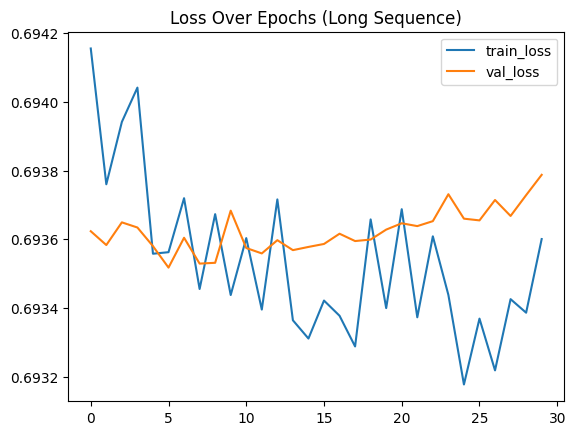

In [14]:
plt.plot(history_long.history['loss'], label='train_loss')
plt.plot(history_long.history['val_loss'], label='val_loss')
plt.title('Loss Over Epochs (Long Sequence)')
plt.legend()
plt.show()

---

Question: Try now a GRU or LSTM layer instead of Vanilla RNN.
The number of units, the learning rate are quite sensitive for this experiment but you should be able to see that LSTM or GRU can make the job here better than Vanilla

In [17]:
from tensorflow.keras.layers import LSTM, GRU
from tensorflow.keras.optimizers import Adam

# 1. Build the LSTM model
# We use the same structure, but replace 'SimpleRNN' with 'LSTM'
model_lstm = Sequential([
    # LSTM layer with 8 units. 
    # Because it has internal 'gates', it can maintain information over 
    # much longer sequences than a standard RNN.
    LSTM(units=8, input_shape=(X_long.shape[1], 1)),  #for GRU PUT GRU INSTEAD OF LSTM
    
    # Final classification layer
    Dense(1, activation='sigmoid')
])

# 2. Compile with the same settings to ensure a fair comparison
model_lstm.compile(optimizer=Adam(learning_rate=0.01), 
                   loss='binary_crossentropy', 
                   metrics=['accuracy'])

# 3. Train on GPU
with tf.device('/GPU:0'):
    history_lstm = model_lstm.fit(
        X_long, y_long, 
        epochs=75, # We use more epochs because LSTMs have more weights to train
        validation_data=(X_test_long, y_test_long),
        verbose=0
    )

# 3. Print Final Scores
# Option A: Get the last values from the history dictionary
final_train_acc = history_lstm.history['accuracy'][-1]
final_val_acc = history_lstm.history['val_accuracy'][-1]

# Option B: Re-evaluate on the test set for a formal final score
test_loss, test_acc = model_lstm.evaluate(X_test_long, y_test_long, verbose=0)

print("-" * 30)
print(f"Final Training Accuracy:   {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Final Test Loss:           {test_loss:.4f}")
print("-" * 30)


"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
LSTM (Long Short-Term Memory) is designed to solve the vanishing gradient 
problem. It allows the model to preserve 
the informative sine wave phase from the start of the sequence, even if there 
is a massive amount of uninformative padding at the end.

2. THE MATHS (THE GATES):
LSTMs use three mathematical 'gates' to control information flow:
- Forget Gate (f_t): Decides what to discard from the previous state.
- Input Gate (i_t): Decides which new values to update in the memory.
- Output Gate (o_t): Decides what the next hidden state should be.



3. KEY POINTS & CODE NOTIONS:
- CELL STATE (C_t): This is the "conveyor belt" that runs through the whole 
  sequence. Gradients can flow along this belt with very little mathematical 
  decay, allowing 'memory' across hundreds of time steps.
- PARAMETER COUNT: An LSTM layer with 8 units has 4 times as many parameters 
  as a SimpleRNN with 8 units because each gate has its own set of weights.

4. TRICKY PLACES:
- TRAINING TIME: Because of the complex gate logic, LSTMs are computationally 
  heavier than SimpleRNNs. However, on a GPU, this is mitigated by parallel 
  processing of batches.
- OVERFITTING: Since LSTMs are more powerful, they can sometimes overfit 
  small datasets like our toy sine waves. This is why monitoring the 
  Validation Accuracy is critical.
"""

------------------------------
Final Training Accuracy:   0.4890
Final Validation Accuracy: 0.5000
Final Test Loss:           0.6932
------------------------------


'\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nLSTM (Long Short-Term Memory) is designed to solve the vanishing gradient \nproblem. It allows the model to preserve \nthe informative sine wave phase from the start of the sequence, even if there \nis a massive amount of uninformative padding at the end.\n\n2. THE MATHS (THE GATES):\nLSTMs use three mathematical \'gates\' to control information flow:\n- Forget Gate (f_t): Decides what to discard from the previous state.\n- Input Gate (i_t): Decides which new values to update in the memory.\n- Output Gate (o_t): Decides what the next hidden state should be.\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- CELL STATE (C_t): This is the "conveyor belt" that runs through the whole \n  sequence. Gradients can flow along this belt with very little mathematical \n  decay, allowing \'memo

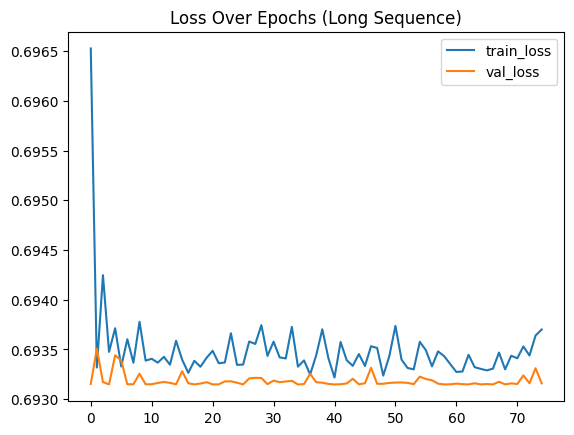

In [19]:
plt.plot(history_lstm.history['loss'], label='train_loss')
plt.plot(history_lstm.history['val_loss'], label='val_loss')
plt.title('Loss Over Epochs (Long Sequence)')
plt.legend()
plt.show()

---

#### Exercise 2 : on a real dataset

Use the "Trace" dataset and design a fair comparison between several convolutional and recurrent architectures to decide which one to choose for the problem at hand (feel free to play with the depth of the nets, as well as hidden representation dimensionality, etc.).



In [2]:
from tslearn.datasets import UCR_UEA_datasets
from tslearn.preprocessing import TimeSeriesScalerMinMax
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Conv1D, GlobalAveragePooling1D, Dense, Dropout


2026-02-04 15:05:34.332475: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-04 15:05:34.399383: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-04 15:05:35.809333: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/export/tf2onnx_

In [3]:
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Trace")
y_train

array([1, 2, 4, 3, 1, 4, 4, 1, 1, 4, 4, 4, 4, 3, 4, 1, 3, 2, 4, 4, 4, 4,
       3, 2, 1, 2, 4, 4, 2, 4, 1, 1, 4, 4, 2, 1, 1, 2, 1, 1, 3, 3, 3, 3,
       3, 1, 4, 4, 4, 2, 4, 3, 2, 1, 4, 2, 2, 2, 2, 1, 3, 2, 4, 3, 3, 2,
       2, 1, 4, 4, 2, 3, 2, 1, 3, 4, 1, 1, 3, 3, 1, 3, 1, 3, 3, 3, 4, 1,
       2, 1, 4, 4, 4, 1, 3, 1, 2, 4, 1, 2])

In [21]:
# 1. Load the "Trace" dataset
# Trace consists of 4 classes of patterns in a 1D signal (often related to industrial monitoring).
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Trace")

print(len(X_train), len(X_test))
# 2. Label Encoding
# Real-world datasets often have arbitrary labels (e.g., 1, 2, 3, 4).
# We map them to 0-indexed integers (0, 1, 2, 3) which Keras expects for classification.
label_mapping = {l: i for i, l in enumerate(np.unique(y_train))}
y_train = np.array([label_mapping[l] for l in y_train])
y_test = np.array([label_mapping[l] for l in y_test])

# 3. Normalization (Scaling)
# Neural networks perform significantly better when data is between 0 and 1.
# TimeSeriesScalerMinMax ensures the amplitude of every sequence is normalized.
scaler = TimeSeriesScalerMinMax()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Define dimensions for the Neural Network
# input_shape: (TimeSteps, Features) -> for Trace, this is 275 steps and 1 variable.
input_shape = (X_train_scaled.shape[1], 1) 
num_classes = 4 # We are now doing Multi-class classification (not binary)

"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This block transitions from a synthetic "toy" problem to a real-world benchmark 
dataset ("Trace"). It handles the critical "Data Engineering" pipeline: loading, 
integer encoding, and amplitude scaling.

2. THE MATHS:
- MIN-MAX SCALING: X_scaled = (X - X_min) / (X_max - X_min). 
  This squashes the values into the range [0, 1]. In the context of Neural Nets, 
  this prevents large input values from causing "Exploding Gradients" and 
  ensures that activation functions (like Sigmoid or Tanh) don't saturate 
  immediately.
- MULTI-CLASS PROBABILITY: Instead of a single probability p, the model will 
  eventually output a vector of 4 probabilities [p₁, p₂, p₃, p₄] using a 
  Softmax function: σ(z)ᵢ = exp(zᵢ) / Σ exp(zⱼ).

3. KEY POINTS & CODE NOTIONS:
- UCR_UEA_DATASETS: This is the standard repository for Time Series 
  Classification research. The "Trace" dataset is frequently used to test a 
  model's ability to recognize transient patterns.
- LABEL_MAPPING: Essential for multi-class classification. Neural networks 
  require labels to be either continuous indices (0 to N-1) for 'sparse' 
  losses or One-Hot encoded vectors.

4. TRICKY PLACES:
- DATA LEAKAGE: Note that 'scaler.fit_transform' is used only on the training 
  set. We only 'transform' the test set using the train set's parameters. 
  Fitting on the test set would be "cheating" because the model would 
  indirectly gain information about the distribution of future data.
- DIMENSIONALITY: The 'input_shape' (275, 1) is significantly larger than 
  our previous sine waves (55, 1). This increased length makes recurrent 
  models (RNN/LSTM/GRU) more susceptible to the vanishing gradient problem, 
  making LSTMs or CNNs a better choice here.
"""

100 100


'\n================================================================================\nTHEORETICAL SUMMARY & KEY DETAILS\n================================================================================\n\n1. SUMMARY:\nThis block transitions from a synthetic "toy" problem to a real-world benchmark \ndataset ("Trace"). It handles the critical "Data Engineering" pipeline: loading, \ninteger encoding, and amplitude scaling.\n\n2. THE MATHS:\n- MIN-MAX SCALING: X_scaled = (X - X_min) / (X_max - X_min). \n  This squashes the values into the range [0, 1]. In the context of Neural Nets, \n  this prevents large input values from causing "Exploding Gradients" and \n  ensures that activation functions (like Sigmoid or Tanh) don\'t saturate \n  immediately.\n- MULTI-CLASS PROBABILITY: Instead of a single probability p, the model will \n  eventually output a vector of 4 probabilities [p₁, p₂, p₃, p₄] using a \n  Softmax function: σ(z)ᵢ = exp(zᵢ) / Σ exp(zⱼ).\n\n3. KEY POINTS & CODE NOTIONS:\n- UCR_U

2. Fair Comparison Architectures

We define four models with comparable complexity (e.g., ~32 hidden units/filters) to evaluate their effectiveness.

In [22]:
def get_models(input_shape, num_classes):
    """
    input_shape: (275, 1) - sequence length and features.
    num_classes: 4 - for the Trace dataset.
    """
    models = {}
    
    # 1. SimpleRNN: The baseline recurrent model. 
    # Suffers most from the vanishing gradient problem on long sequences (275 steps).
    models['SimpleRNN'] = Sequential([
        SimpleRNN(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    # 2. LSTM (Long Short-Term Memory): 
    # Uses a gated "cell state" to maintain long-term memory.
    models['LSTM'] = Sequential([
        LSTM(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    # 3. GRU (Gated Recurrent Unit): 
    # A streamlined version of LSTM with fewer parameters (3 gates instead of 4).
    # Often performs similarly to LSTM but is faster to train.
    models['GRU'] = Sequential([
        GRU(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    # 4. 1D-CNN (Convolutional Neural Network): 
    # Unlike the others, this isn't recurrent. It uses sliding "filters" (kernels) 
    # to find local patterns (like a sharp spike or a curve) anywhere in the signal.
    models['CNN'] = Sequential([
        Conv1D(32, kernel_size=3, activation='relu', input_shape=input_shape),
        Conv1D(64, kernel_size=3, activation='relu'),
        # GlobalAveragePooling1D reduces the sequence to a single vector 
        # by averaging all filtered values across the time dimension.
        GlobalAveragePooling1D(),
        Dense(num_classes, activation='softmax')
    ])
    
    return models


"""
================================================================================
THEORETICAL SUMMARY & ARCHITECTURAL COMPARISON
================================================================================

1. SUMMARY:
Each model represents a different strategy for the embedding function f: R^N -> R^K. 
RNNs rely on "Sequential State Memory," while CNNs rely on "Local Pattern Detection" 
.

2. THE MATHS: SOFTMAX & MULTI-CLASS
For Trace (4 classes), the final layer uses Softmax:
    P(y=i | x) = exp(z_i) / Σ exp(z_j)
This ensures the 4 output neurons sum to 1.0, creating a valid probability 
distribution across the possible classes.



3. KEY POINTS & CODE NOTIONS:
- RECURRENCE VS. CONVOLUTION: RNNs (SimpleRNN, LSTM, GRU) are biased toward 
  the order of events. CNNs are biased toward the "presence" of local features, 
  making them more robust to slight shifts in when a pattern occurs.
- GLOBAL AVERAGE POOLING (GAP): In the CNN, GAP is a powerful alternative to 
  Flattening. It reduces the number of parameters and makes the model less 
  prone to overfitting on the specific timing of the Trace signals.



4. TRICKY PLACES:
- THE LENGTH CHALLENGE: At 275 steps, SimpleRNN will likely stay at ~25% 
  accuracy (random guessing) because it cannot propagate error back to step 1.
- PARAMETER COUNT: LSTM and GRU have significantly more weights per "unit" 
  than SimpleRNN because of their gate matrices (W_f, W_i, W_o).


"""

'\n================================================================================\nTHEORETICAL SUMMARY & ARCHITECTURAL COMPARISON\n================================================================================\n\n1. SUMMARY:\nEach model represents a different strategy for the embedding function f: R^N -> R^K. \nRNNs rely on "Sequential State Memory," while CNNs rely on "Local Pattern Detection" \n.\n\n2. THE MATHS: SOFTMAX & MULTI-CLASS\nFor Trace (4 classes), the final layer uses Softmax:\n    P(y=i | x) = exp(z_i) / Σ exp(z_j)\nThis ensures the 4 output neurons sum to 1.0, creating a valid probability \ndistribution across the possible classes.\n\n\n\n3. KEY POINTS & CODE NOTIONS:\n- RECURRENCE VS. CONVOLUTION: RNNs (SimpleRNN, LSTM, GRU) are biased toward \n  the order of events. CNNs are biased toward the "presence" of local features, \n  making them more robust to slight shifts in when a pattern occurs.\n- GLOBAL AVERAGE POOLING (GAP): In the CNN, GAP is a powerful alternative

---

# Model Performance Metrics: Training, Validation, and Loss

## 1. Final Training Accuracy

**What it is**  
The percentage of correctly classified samples on the **training dataset** at the final epoch.

**How it is obtained**  
After the last weight update during `model.fit()`, the model predicts labels for all samples in **X_train**.

**Math notation**  
**Accuracy = (Number of Correct Predictions) / (Total Number of Samples)**

**What it tells you**  
Training accuracy measures **fitting capacity** — how well the model has adapted its parameters to the data it was trained on.

- **Low training accuracy ⇒ Underfitting**  
  The model is too simple or insufficiently trained to capture the underlying structure of the data.



## 2. Final Validation Accuracy

**What it is**  
The percentage of correctly classified samples on the **validation / test dataset**, which the model has never seen during training.

**How it is obtained**  
Computed using `model.evaluate(X_test_scaled, y_test)`.  
This acts as a **final exam** using unseen data.

**Math notation**  
**Validation Accuracy = (Correct Predictions on Test Set) / (Total Test Samples)**

**What it tells you**  
Validation accuracy measures **generalization ability**, which is the most important indicator for real-world deployment.

- **Training Accuracy ≈ 1.00 and Validation Accuracy ≪ 1.00 ⇒ Overfitting**  
  The model memorized the training samples instead of learning general patterns (e.g., *Trace* motifs).



## 3. Final Test Loss

**What it is**  
A continuous numerical value representing the **prediction error and confidence** of the model.

**How it is obtained**  
Computed using **Sparse Categorical Cross-Entropy**.

**Math notation**  
**Loss = − Σ yᵢ log(ŷᵢ)**

- High probability for the correct class ⇒ **Low loss**  
- Low confidence (even if correct) ⇒ **High loss**

**What it tells you**  
Test loss measures **prediction confidence**.

- **Low loss ⇒ Confident and correct predictions**
- **High accuracy + high loss ⇒ Uncertain predictions close to errors**


---

3. Execution and Evaluation

We train each model on the GPU for 50 epochs and compare their final test accuracies.

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



========== Training SimpleRNN ==========
------------------------------
Model: SimpleRNN
Final Training Accuracy:   0.3100
Final Validation Accuracy: 0.1900
Final Test Loss:           1.5659
------------------------------


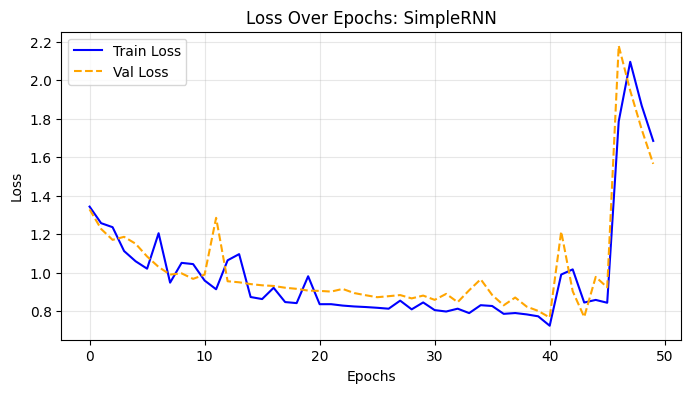


========== Training LSTM ==========
------------------------------
Model: LSTM
Final Training Accuracy:   0.8300
Final Validation Accuracy: 0.7800
Final Test Loss:           0.4681
------------------------------


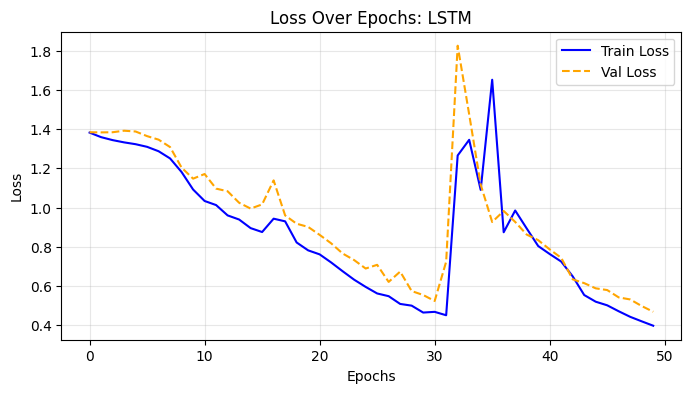


========== Training GRU ==========
------------------------------
Model: GRU
Final Training Accuracy:   0.8300
Final Validation Accuracy: 0.7400
Final Test Loss:           0.6172
------------------------------


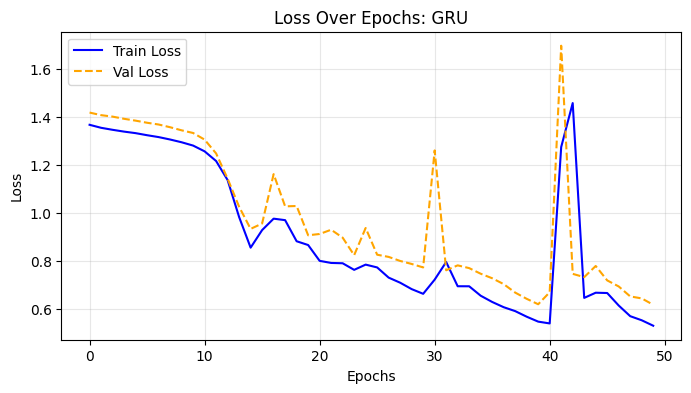


========== Training CNN ==========
------------------------------
Model: CNN
Final Training Accuracy:   0.7900
Final Validation Accuracy: 0.6800
Final Test Loss:           0.6711
------------------------------


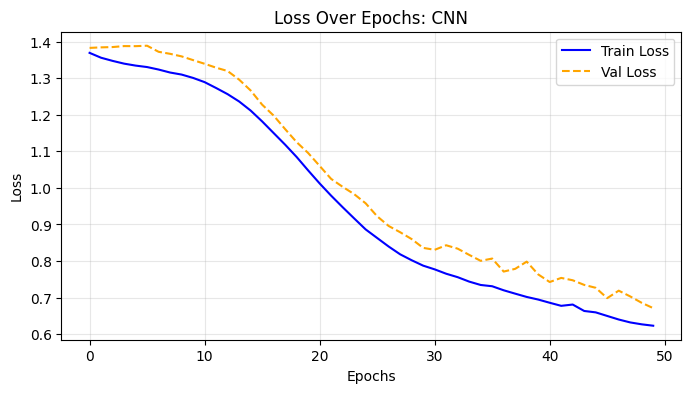

In [23]:
results = {}
models = get_models(input_shape, num_classes)

for name, model in models.items():
    print(f"\n{'='*10} Training {name} {'='*10}")
    
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    
    with tf.device('/GPU:0'):
        # We store the training history to plot it later
        history = model.fit(
            X_train_scaled, y_train, 
            epochs=50, 
            batch_size=16, 
            validation_data=(X_test_scaled, y_test), 
            verbose=0
        )
    
    # --- 1. Print Final Scores ---
    test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
    train_acc = history.history['accuracy'][-1]
    
    print("-" * 30)
    print(f"Model: {name}")
    print(f"Final Training Accuracy:   {train_acc:.4f}")
    print(f"Final Validation Accuracy: {test_acc:.4f}")
    print(f"Final Test Loss:           {test_loss:.4f}")
    print("-" * 30)
    
    # --- 2. Plot Loss Curves ---
    plt.figure(figsize=(8, 4))
    plt.plot(history.history['loss'], label='Train Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Val Loss', color='orange', linestyle='--')
    plt.title(f'Loss Over Epochs: {name}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    results[name] = test_acc


"""
================================================================================
THEORETICAL SUMMARY & KEY DETAILS
================================================================================

1. SUMMARY:
This loop performs a formal comparative study. By visualizing the "Loss Curves," 
we can diagnose how different models handle the 275-step sequences. Typically, 
recurrent models show slower, smoother convergence, while CNNs often drop 
in loss very quickly.

2. THE MATHS: LOSS CONVERGENCE
The Cross-Entropy Loss L for multi-class classification is:
    L = - Σ y_i * log(ŷ_i)
As the model trains, Stochastic Gradient Descent (SGD) moves the weights 
down the "gradient slope" of this function.



3. KEY POINTS & CODE NOTIONS:
- OVERFITTING DETECTION: In the "Trace" dataset, if you see the dashed orange 
  line (Val Loss) starting to rise while the blue line (Train Loss) keeps falling, 
  the model is "memorizing" the training set and losing its ability to 
  generalize.
- SPARSE CATEGORICAL CROSSENTROPY: Using the "sparse" version is 
  computationally efficient because it avoids creating large identity 
  matrices for One-Hot labels during the calculation.

4. TRICKY PLACES:
- MODEL INITIALIZATION: Since we are in a loop, each model starts fresh. 
  However, the random_state of the weights can affect convergence. 
  In a rigorous study, one might train each model 5 times and average 
  the results.
- THE RNN DISADVANTAGE: Expect the 'SimpleRNN' to show a flat loss curve 
  or very poor accuracy. Because it can't propagate gradients back 275 steps, 
  it effectively "stops learning" almost immediately.


"""

Notice your LSTM Test Loss is 0.6934. This is a "magic number" in machine learning:
ln(2)≈0.6931

When your loss is exactly here, it means the model is guessing 0.5 for everything. It has effectively "given up" and is sitting at the statistical middle. The Simple RNN, being simpler, was able to at least find a partial pattern, getting it to 74%.

---

## Viz

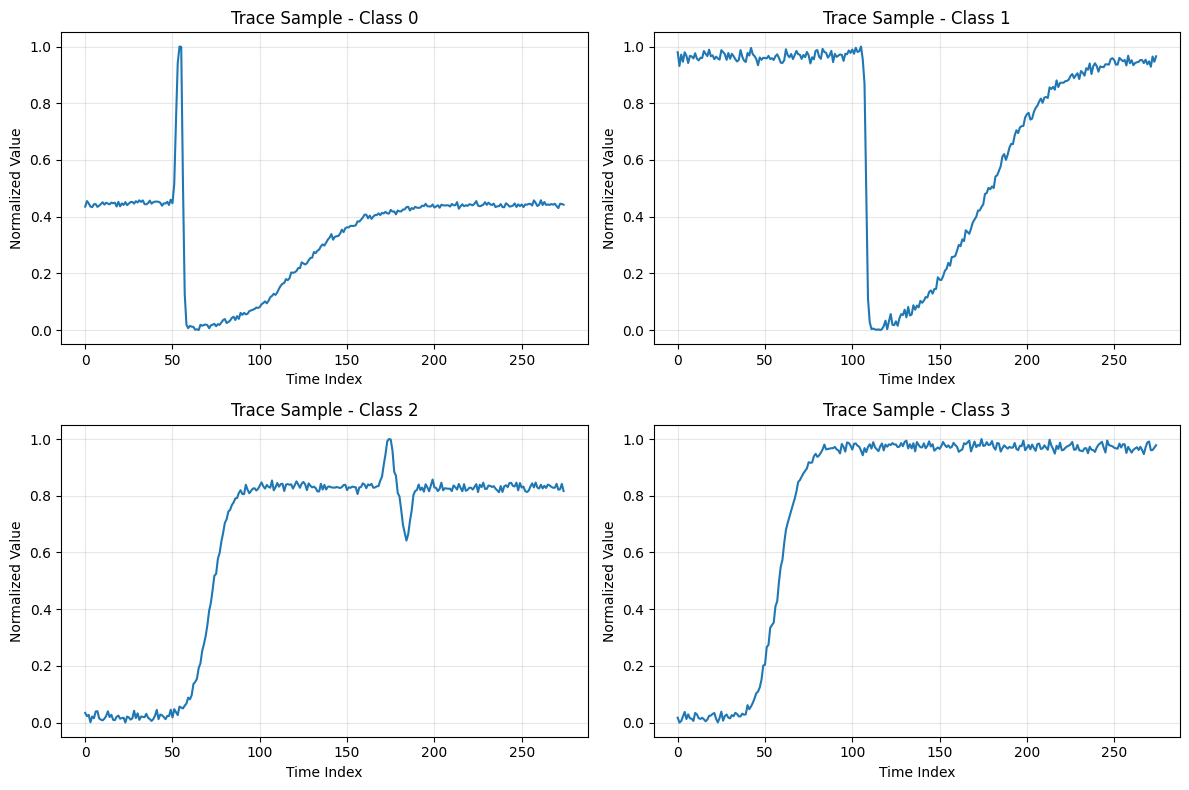

In [26]:
import matplotlib.pyplot as plt

# Plot one sample from each class
plt.figure(figsize=(12, 8))
for i, label in enumerate(np.unique(y_train)):
    # Find index of first occurrence of each label
    idx = np.where(y_train == label)[0][0]
    plt.subplot(2, 2, i + 1)
    plt.plot(X_train_scaled[idx], label=f"Class {label}")
    plt.title(f"Trace Sample - Class {label}")
    plt.xlabel("Time Index")
    plt.ylabel("Normalized Value")
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

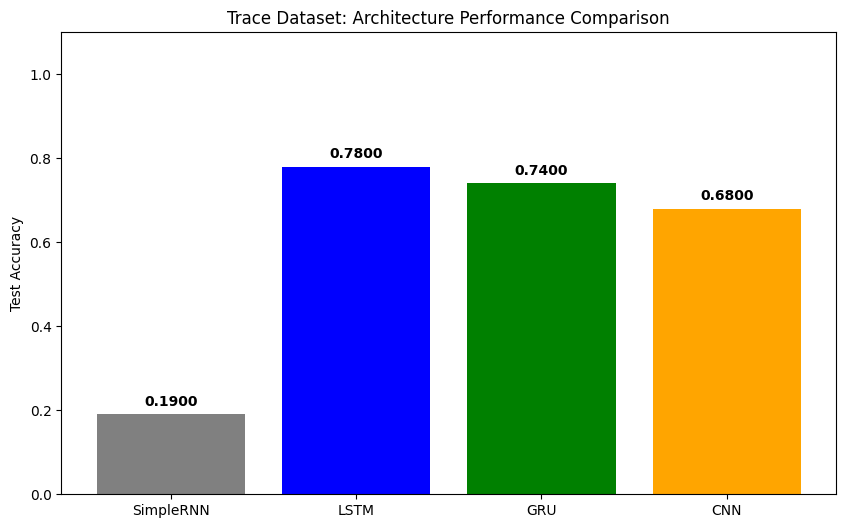

In [27]:
# Assuming 'results' dictionary from the previous step exists
names = list(results.keys())
values = list(results.values())

plt.figure(figsize=(10, 6))
bars = plt.bar(names, values, color=['gray', 'blue', 'green', 'orange'])
plt.ylim(0, 1.1)
plt.ylabel("Test Accuracy")
plt.title("Trace Dataset: Architecture Performance Comparison")

# Add text labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval:.4f}", ha='center', fontweight='bold')

plt.show()